# Subroutine 2

### installing necessary packages

In [1]:
! pip install numpy
! pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
def unit_lower_matvec_cr(arr, v, n):
    """
    Compute w = L v, where L is unit lower triangular stored by compressed rows.

    arr : 1-D array of length n(n-1)/2 holding the strictly lower part of L, row by row:
          [L21, L31, L32, L41, L42, L43, ...]  (diagonal 1s are not stored)
    v   : 1-D array of length n
    n   : order of L
    """
    w = [0.0] * n
    k = 0                           # position in arr, moves forward only

    for i in range(n):
        s = v[i]                    # unit diagonal contribution
        for j in range(i):          # strictly lower part of row i
            s = s + arr[k] * v[j]
            k = k + 1
        w[i] = s

    return w

### Testing using the known result (Basic 4 by 4)

In [4]:
L = [[1, 0, 0, 0],
     [2, 1, 0, 0],
     [3, 4, 1, 0],
     [5, 6, 7, 1]]

arr = [2, 3, 4, 5, 6, 7]  # strictly lower part of L in compressed row format
v = [1, 1, 1, 1]

w = unit_lower_matvec_cr(arr, v, 4)
print ("w =", w)
w_expected = [1, 3, 8, 19]  # expected (row sums, worked out by hand)

if w == w_expected:
    print("yeeee, it works!")
else:
    print("oh no, it failed:", w, "!=", w_expected)  

w = [1, 3, 8, 19]
yeeee, it works!


### Generating random matrix(L), vector(v) and comparing result

In [5]:
import numpy as np
n = int(input("Enter n: "))

rng = np.random.default_rng(seed=42)  # for reproducibility
# Full unit lower triangular matrix (zeros above the diagonal, ones on it)
L = np.tril(rng.random((n, n)), -1) + np.eye(n)

# Compressed-row array: strictly lower entries, row by row
arr = [L[i][j] for i in range(n) for j in range(i)]

# Random vector
v = rng.random(n)

w_comp = np.array(unit_lower_matvec_cr(arr, v, n))   # our routine (uses arr, not L)
w_true = L @ v                                        # NumPy

abs_err = np.linalg.norm(w_comp - w_true)
rel_err = abs_err / np.linalg.norm(w_true)

#print("L (full matrix) =\n", L)
#print("\nStrictly lower elements of L (row by row, no zeros or ones):")
#for i in range(1, n):
#    print(f"row {i+1}:", L[i, :i])
print("\nCompressed array (length n(n-1)/2 =", len(arr), ") =", np.array(arr)) 
print("\nv =", v)
print("\nw computed  =", w_comp)
print("w true =", w_true)
print("absolute error =", abs_err)
print("relative error =", rel_err)


Compressed array (length n(n-1)/2 = 499500 ) = [0.06206311 0.84273197 0.44638949 ... 0.20235086 0.55082789 0.98694171]

v = [0.69881046 0.46152537 0.01528821 0.33601651 0.5869798  0.26051859
 0.7500438  0.8750648  0.89698984 0.21291252 0.51282339 0.46457952
 0.87382376 0.04748846 0.81767924 0.72377743 0.99436839 0.95589542
 0.84069483 0.14233618 0.86069373 0.99533288 0.41289981 0.30481831
 0.012725   0.48503629 0.95477151 0.70904684 0.42357472 0.45344653
 0.51658139 0.44016272 0.38787594 0.12905111 0.58538813 0.69055289
 0.72729193 0.7744362  0.12062934 0.8085027  0.28238116 0.92851896
 0.16528245 0.64909617 0.70511595 0.67921162 0.71927742 0.03426339
 0.23882278 0.23986722 0.13494597 0.70205092 0.60695925 0.79582935
 0.38862508 0.99150938 0.9341912  0.668769   0.5614113  0.35173826
 0.87360721 0.75482273 0.5237787  0.83203427 0.7754511  0.90171025
 0.16269781 0.6125555  0.16141274 0.61751765 0.49397376 0.05964904
 0.26003047 0.36873458 0.40217344 0.10157758 0.76340248 0.86086789
 0.1

In [6]:
step = 10
n_max = n
n_list = list(range(3, n_max + 3, step))
K = len(n_list)

rng = np.random.default_rng(1)   # reproducible
ntrials = 20

def rel_err(d, w, p):
    """Relative error ||d|| / ||w|| in the p-norm (falls back to absolute if ||w|| = 0)."""
    a = np.linalg.norm(d, p)
    b = np.linalg.norm(w, p)
    return a / b if b > 0 else a

max_rel2 = np.zeros(K);  mean_rel2 = np.zeros(K)     # L2
max_reli = np.zeros(K);  mean_reli = np.zeros(K)     # L-inf
rel2_all, reli_all = [], []                          # per-n distributions

for k, size in enumerate(n_list):

    r2 = np.zeros(ntrials)
    ri = np.zeros(ntrials)

    for t in range(ntrials):
        # unit lower triangular L
        L = np.eye(size) + np.tril(rng.standard_normal((size, size)), -1)

        # compressed-row array: strictly lower entries, row by row
        arr = [L[i][j] for i in range(size) for j in range(i)]

        # random v, normalized
        v = rng.standard_normal(size)
        v = v / np.linalg.norm(v)

        w_true = L @ v
        w_comp = np.array(unit_lower_matvec_cr(arr, v.tolist(), size))   # our routine 2

        d = w_comp - w_true
        r2[t] = rel_err(d, w_true, 2)
        ri[t] = rel_err(d, w_true, np.inf)

    rel2_all.append(r2);  reli_all.append(ri)
    max_rel2[k], mean_rel2[k] = r2.max(), r2.mean()
    max_reli[k], mean_reli[k] = ri.max(), ri.mean()

all_rel2 = np.concatenate(rel2_all)
all_reli = np.concatenate(reli_all)

print(f"{'Summary statistics':26s}{'L2':>12s}{'L-inf':>12s}")
print(f"{'Mean of mean rel errors':26s}{mean_rel2.mean():12.3e}{mean_reli.mean():12.3e}")
print(f"{'Max of max rel errors':26s}{max_rel2.max():12.3e}{max_reli.max():12.3e}")
print(f"{'All-tests rel error mean':26s}{all_rel2.mean():12.3e}{all_reli.mean():12.3e}")
print(f"{'All-tests rel error var':26s}{all_rel2.var(ddof=1):12.3e}{all_reli.var(ddof=1):12.3e}")

Summary statistics                  L2       L-inf
Mean of mean rel errors      6.400e-16   1.049e-15
Max of max rel errors        1.056e-15   3.407e-15
All-tests rel error mean     6.400e-16   1.049e-15
All-tests rel error var      5.061e-32   2.724e-31


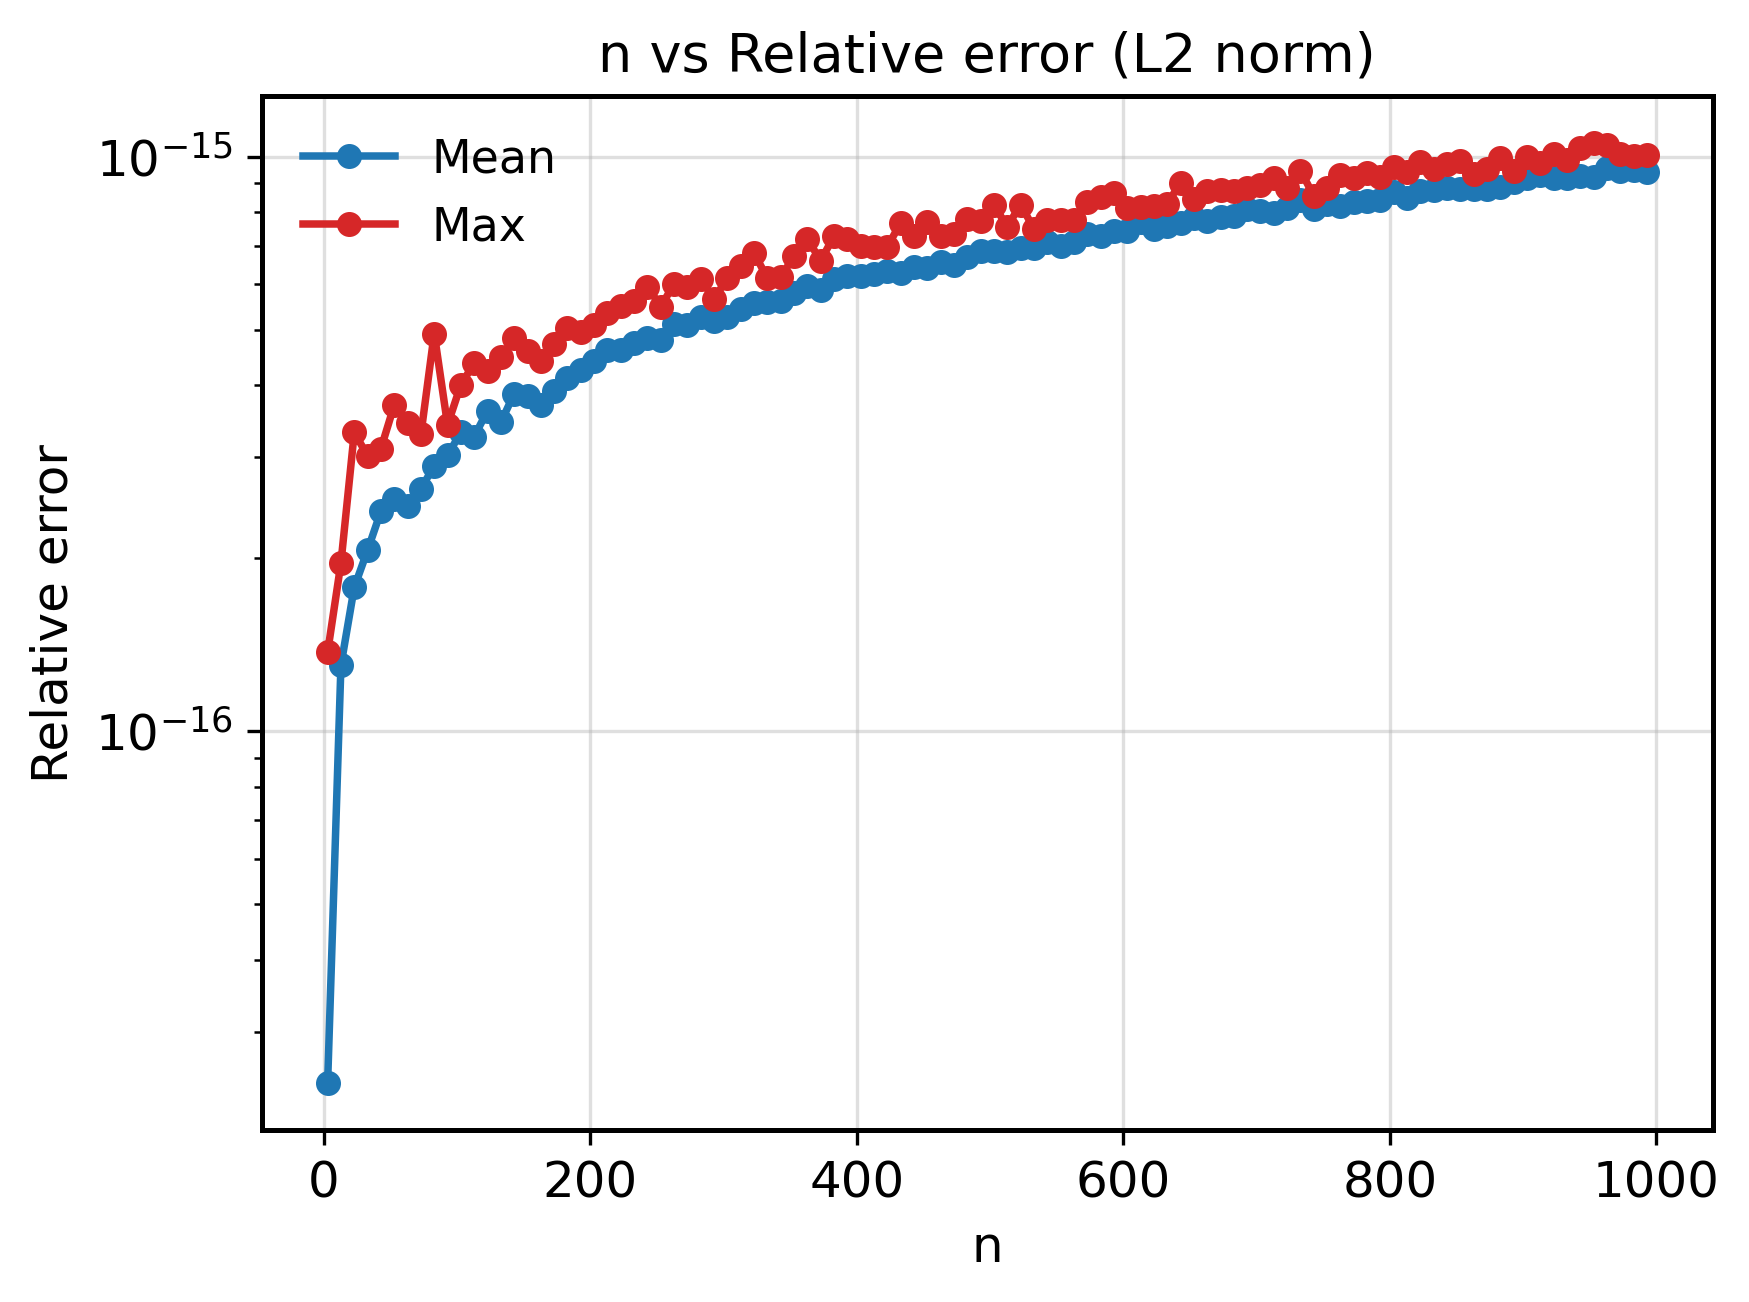

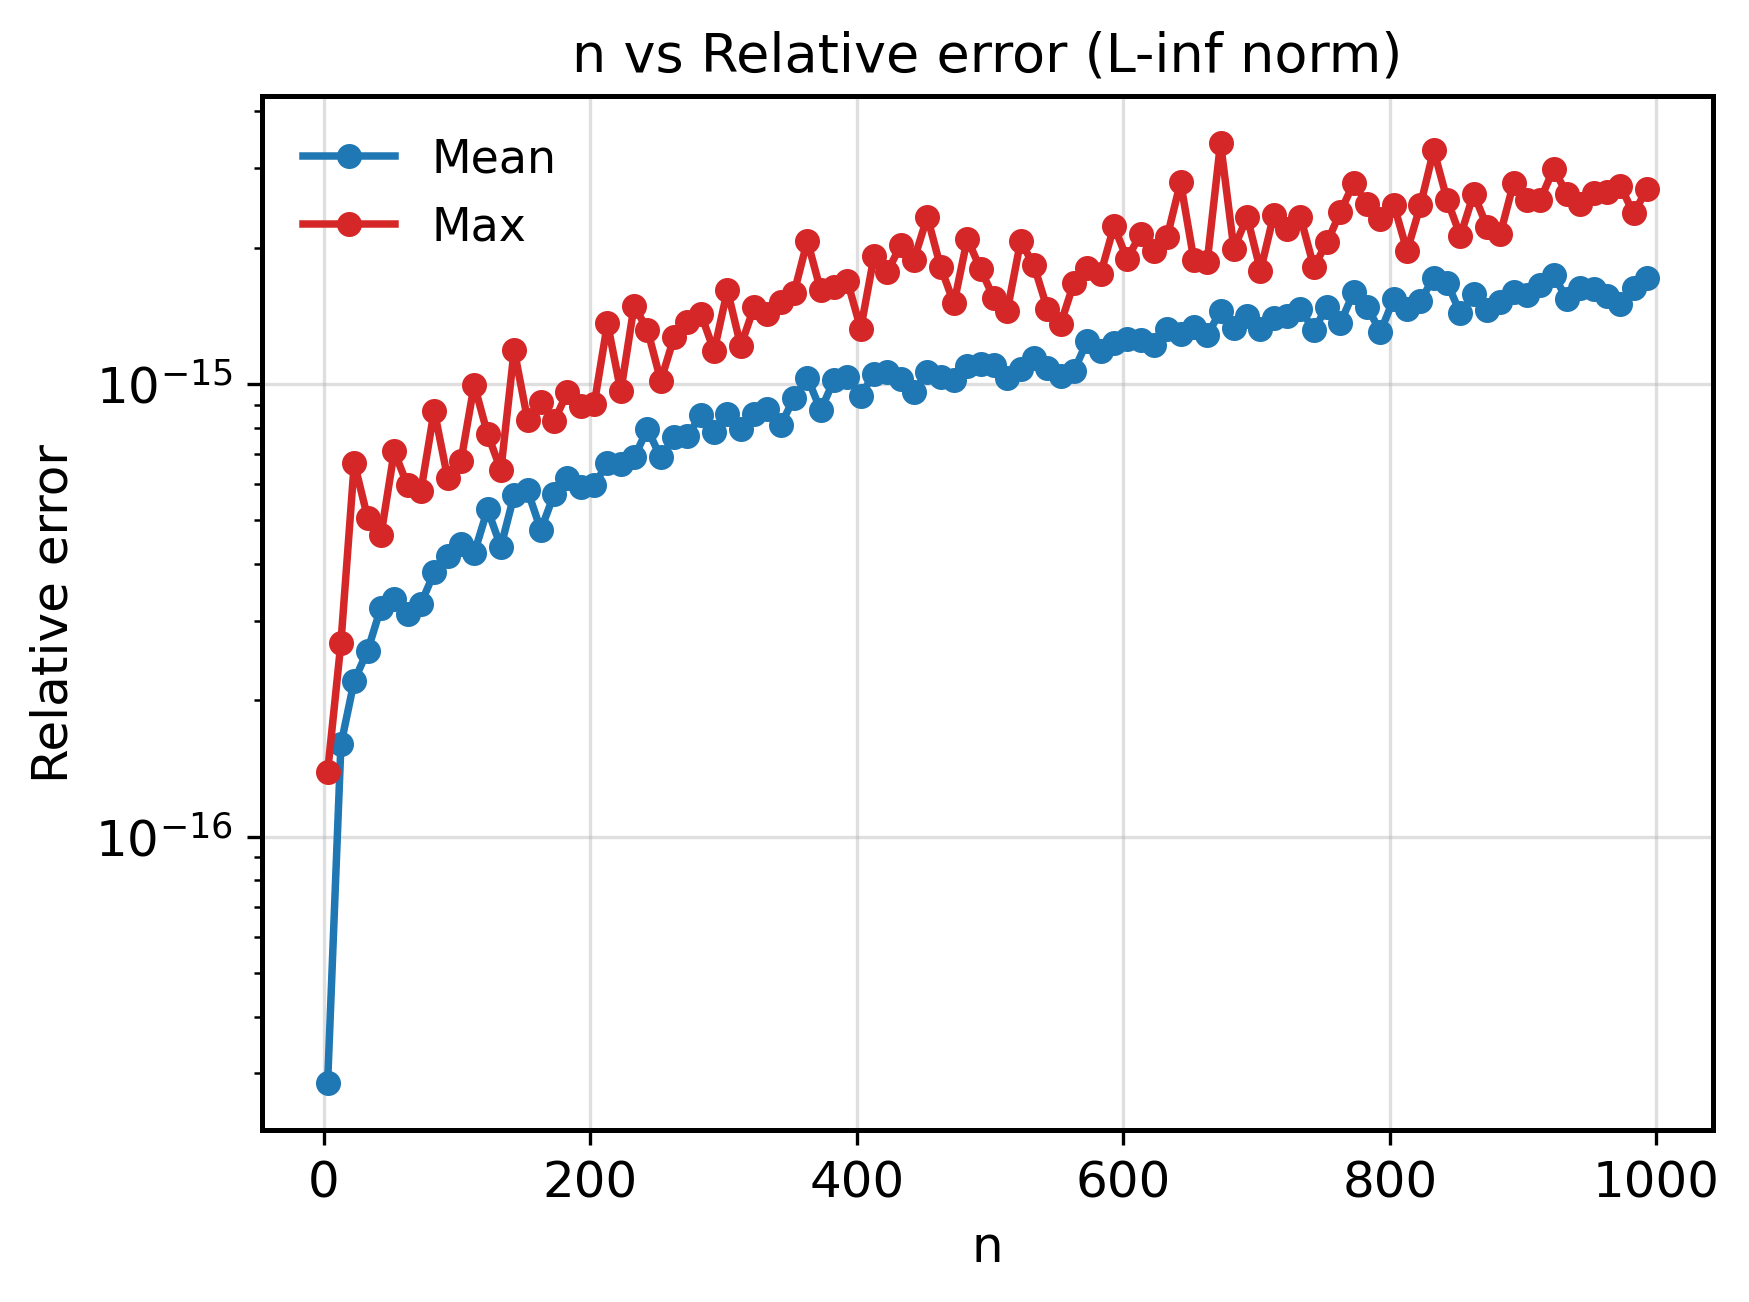

In [10]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "axes.spines.top": True,      # full border on all four sides
    "axes.spines.right": True,
    "axes.linewidth": 1.2,        # slightly thicker border
})

plots = [(mean_rel2, max_rel2, "L2 norm",    "L2"),
         (mean_reli, max_reli, "L-inf norm", "Linf")]

for m, M, name, tag in plots:
    fig, a = plt.subplots(figsize=(6, 4.5))      # one figure per plot

    a.semilogy(n_list, m, "-o", color="#1f77b4", lw=1.8, ms=5, label="Mean")
    a.semilogy(n_list, M, "-o", color="#d62728", lw=1.8, ms=5, label="Max")
    #a.axhline(np.finfo(float).eps, color="gray", ls=":", label="machine epsilon")

    a.set_xlabel("n")
    a.set_ylabel("Relative error")
    a.set_title(f"n vs Relative error ({name})")
    a.grid(True, which="major", alpha=0.4)
    a.legend(frameon=False, loc="best")

    plt.tight_layout()
    plt.savefig(f"subroutine2_error_{tag}_n{n_max}.pdf", bbox_inches="tight")   # vector PDF
    plt.savefig(f"subroutine2_error_{tag}_n{n_max}.png", dpi=300, bbox_inches="tight")
    plt.show()

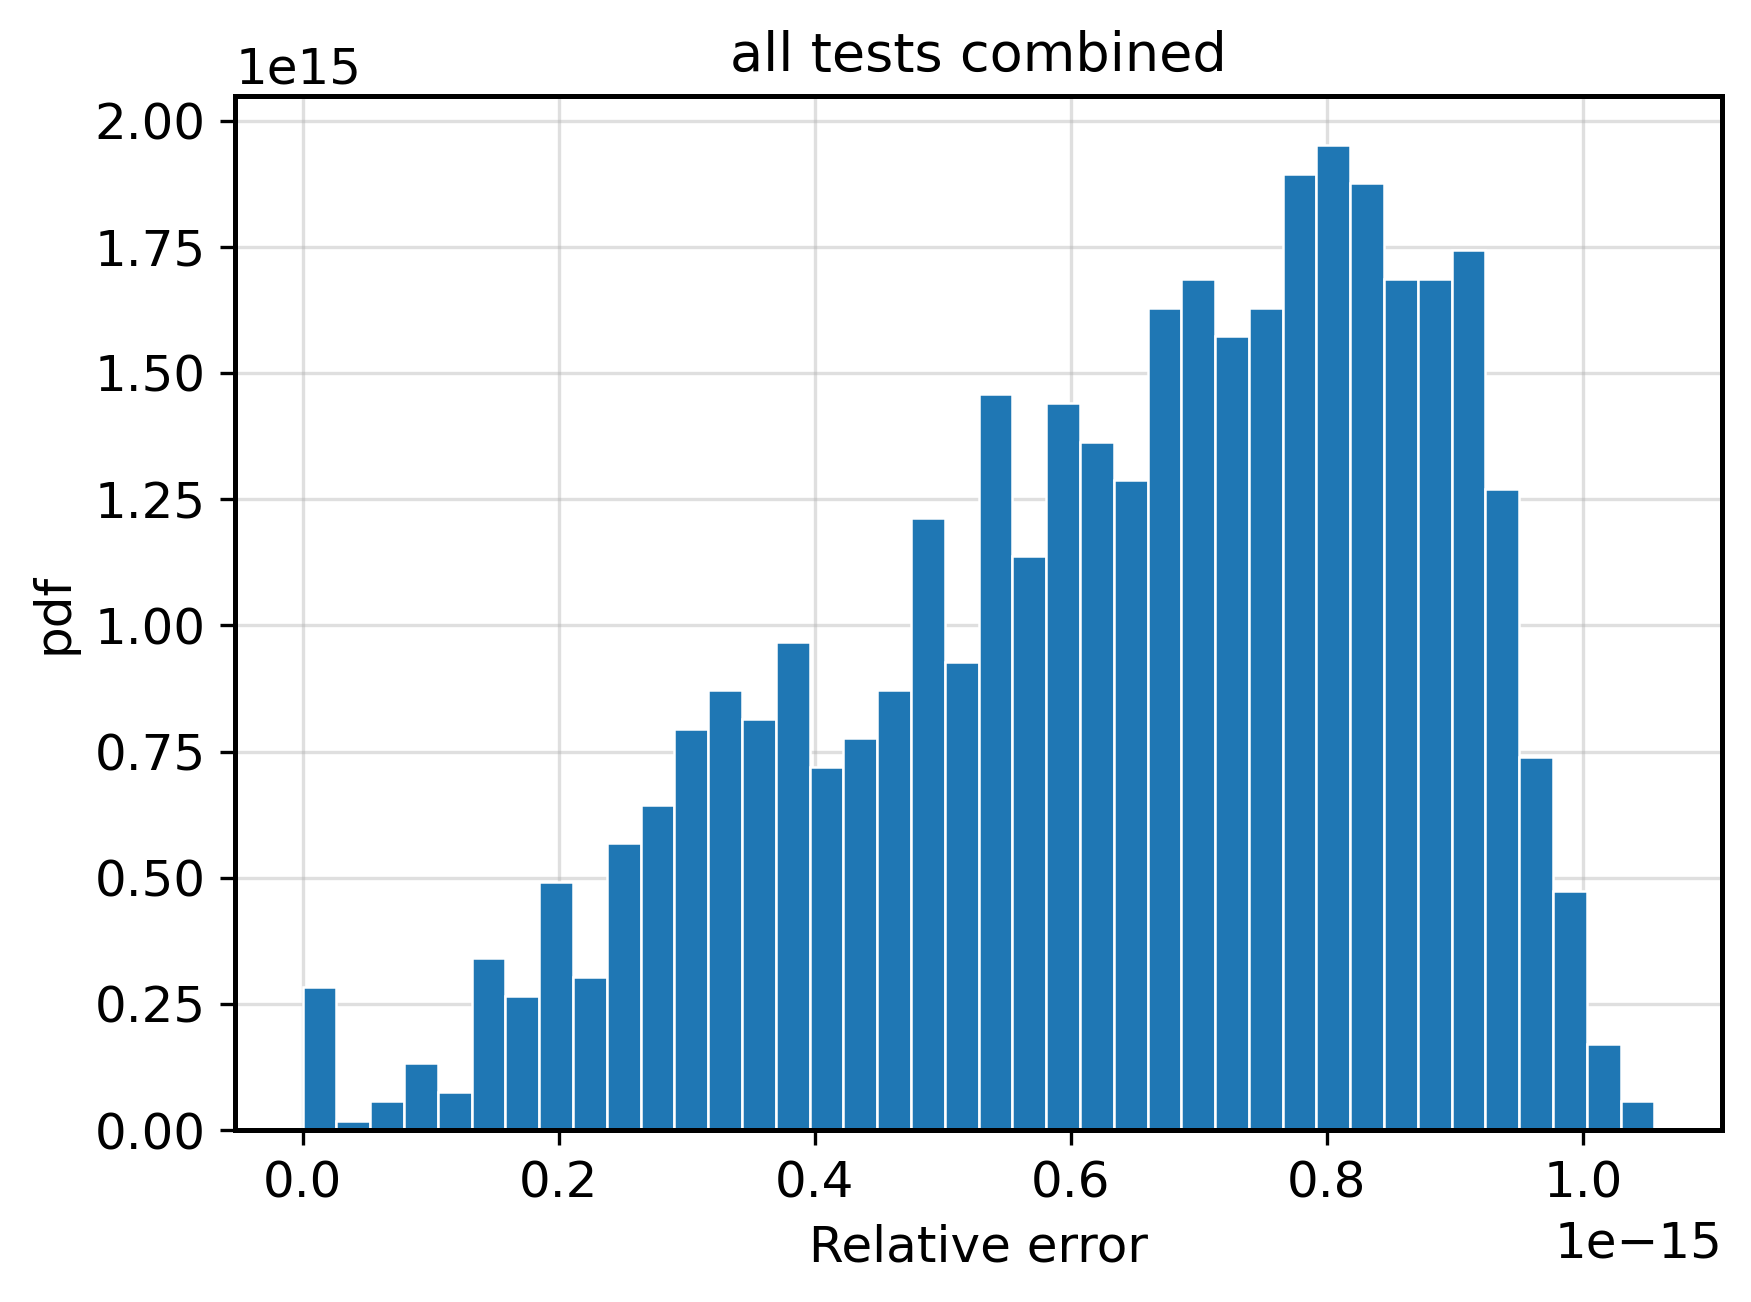

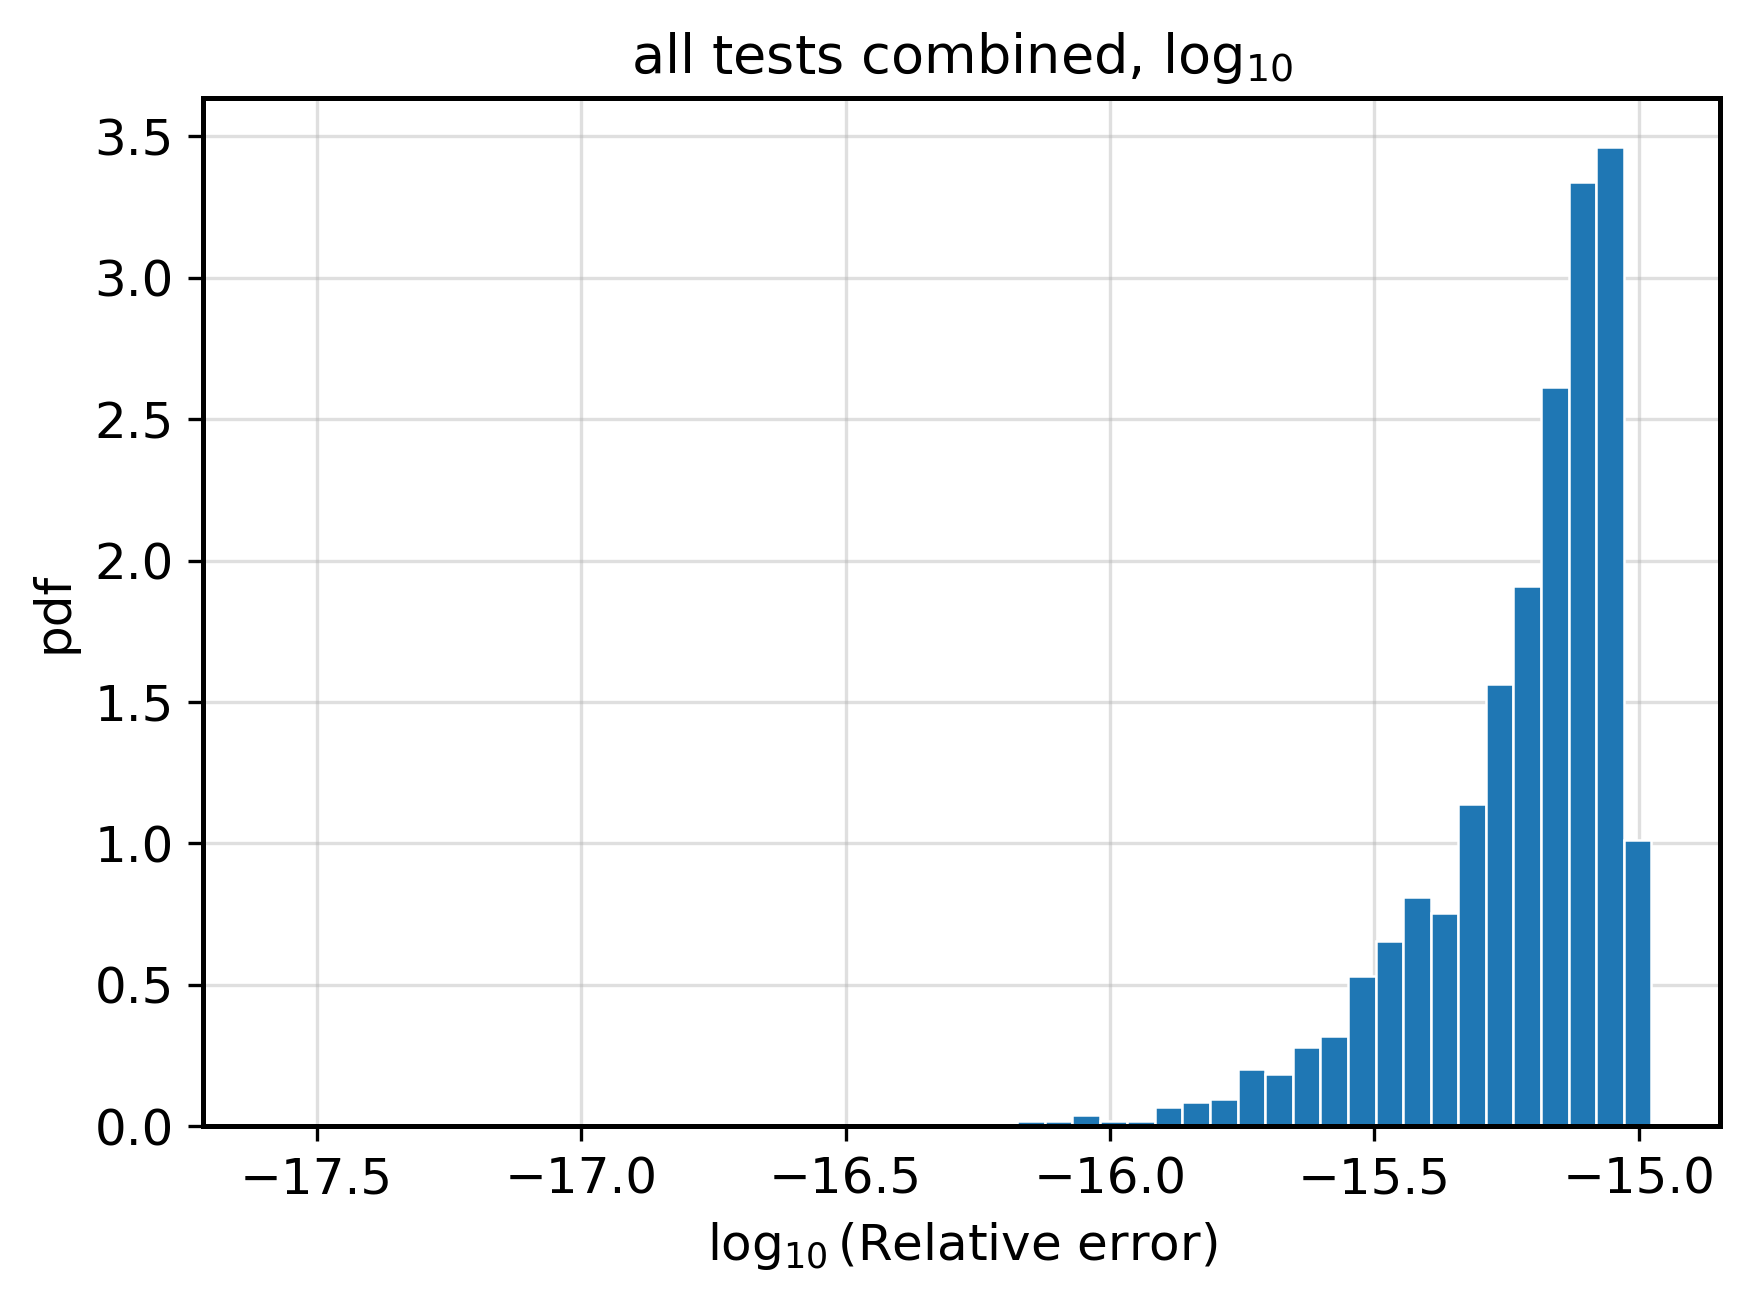

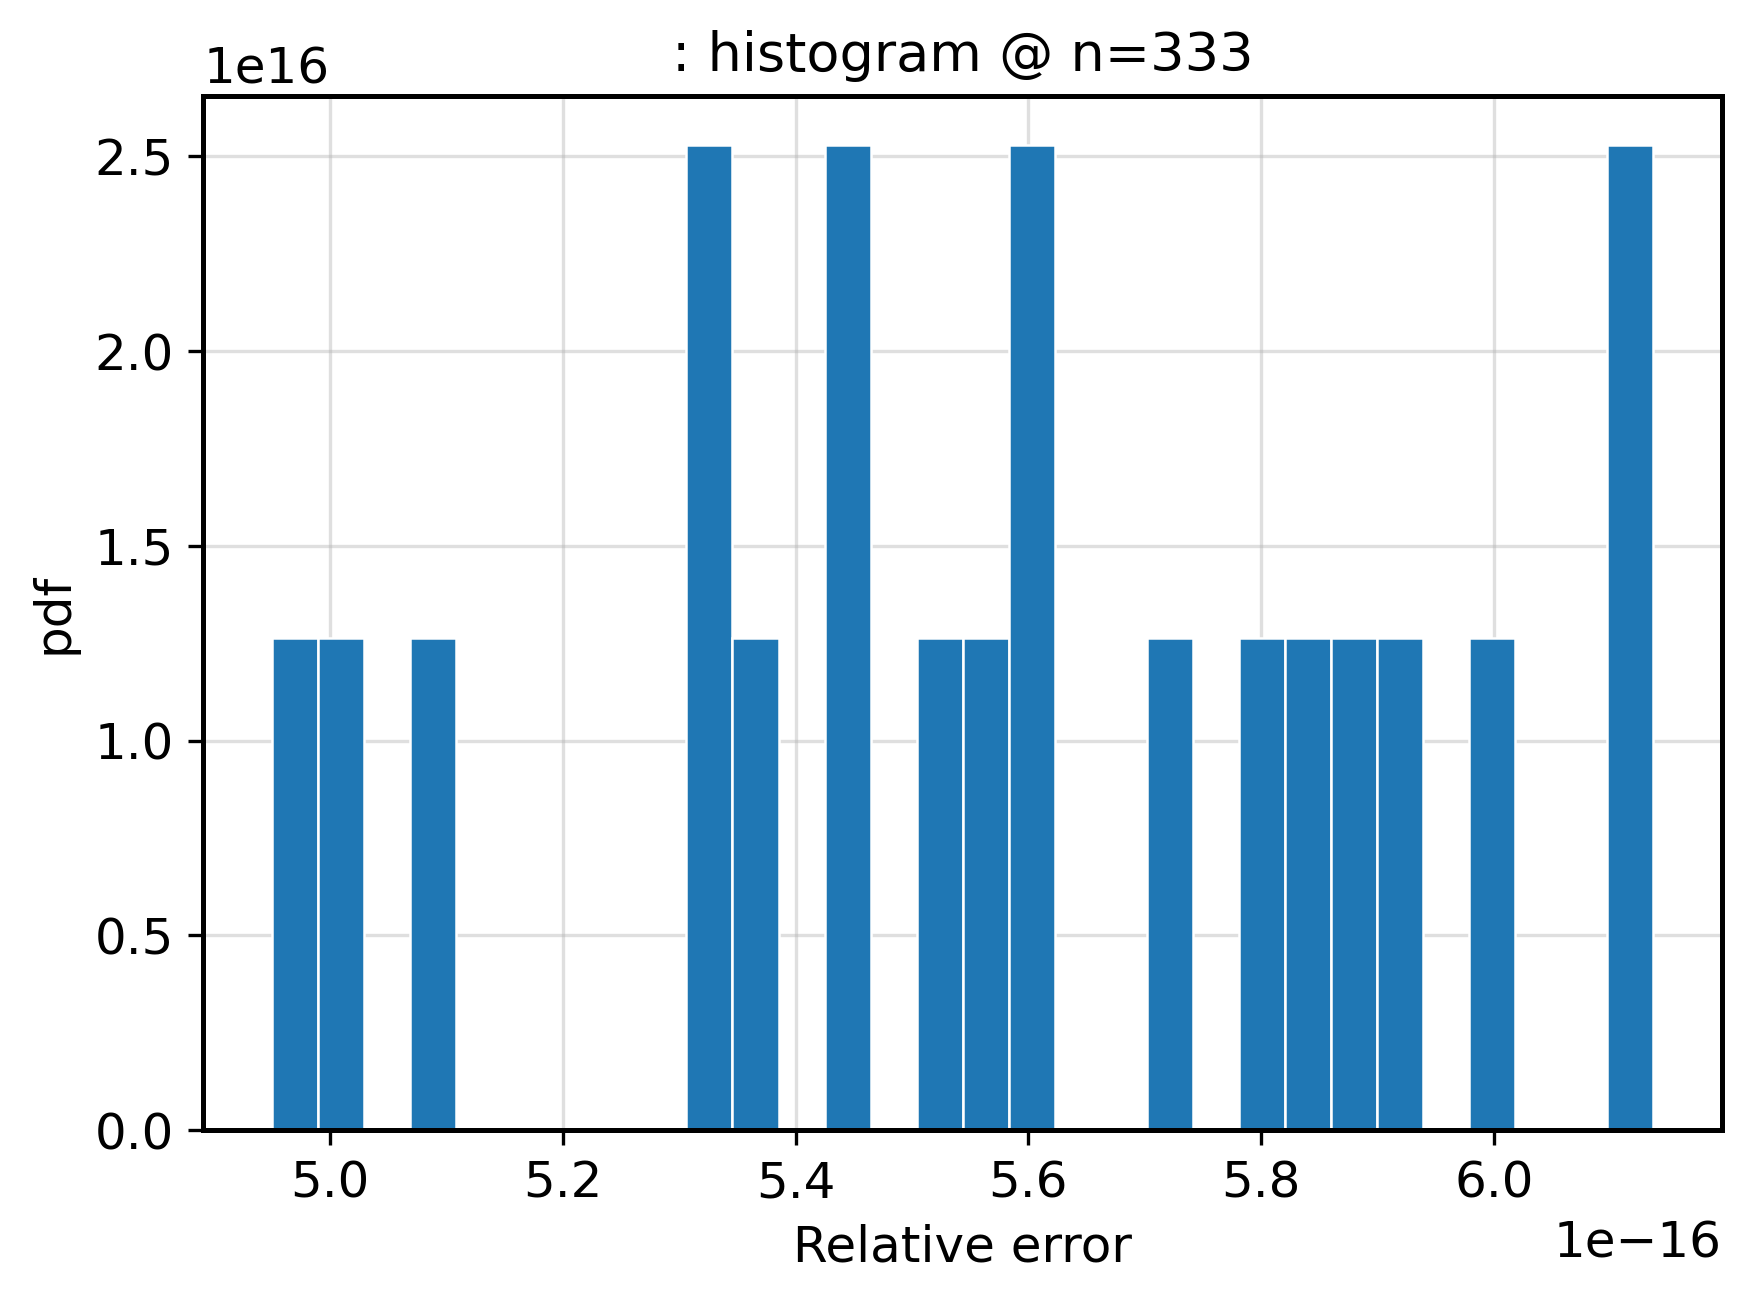

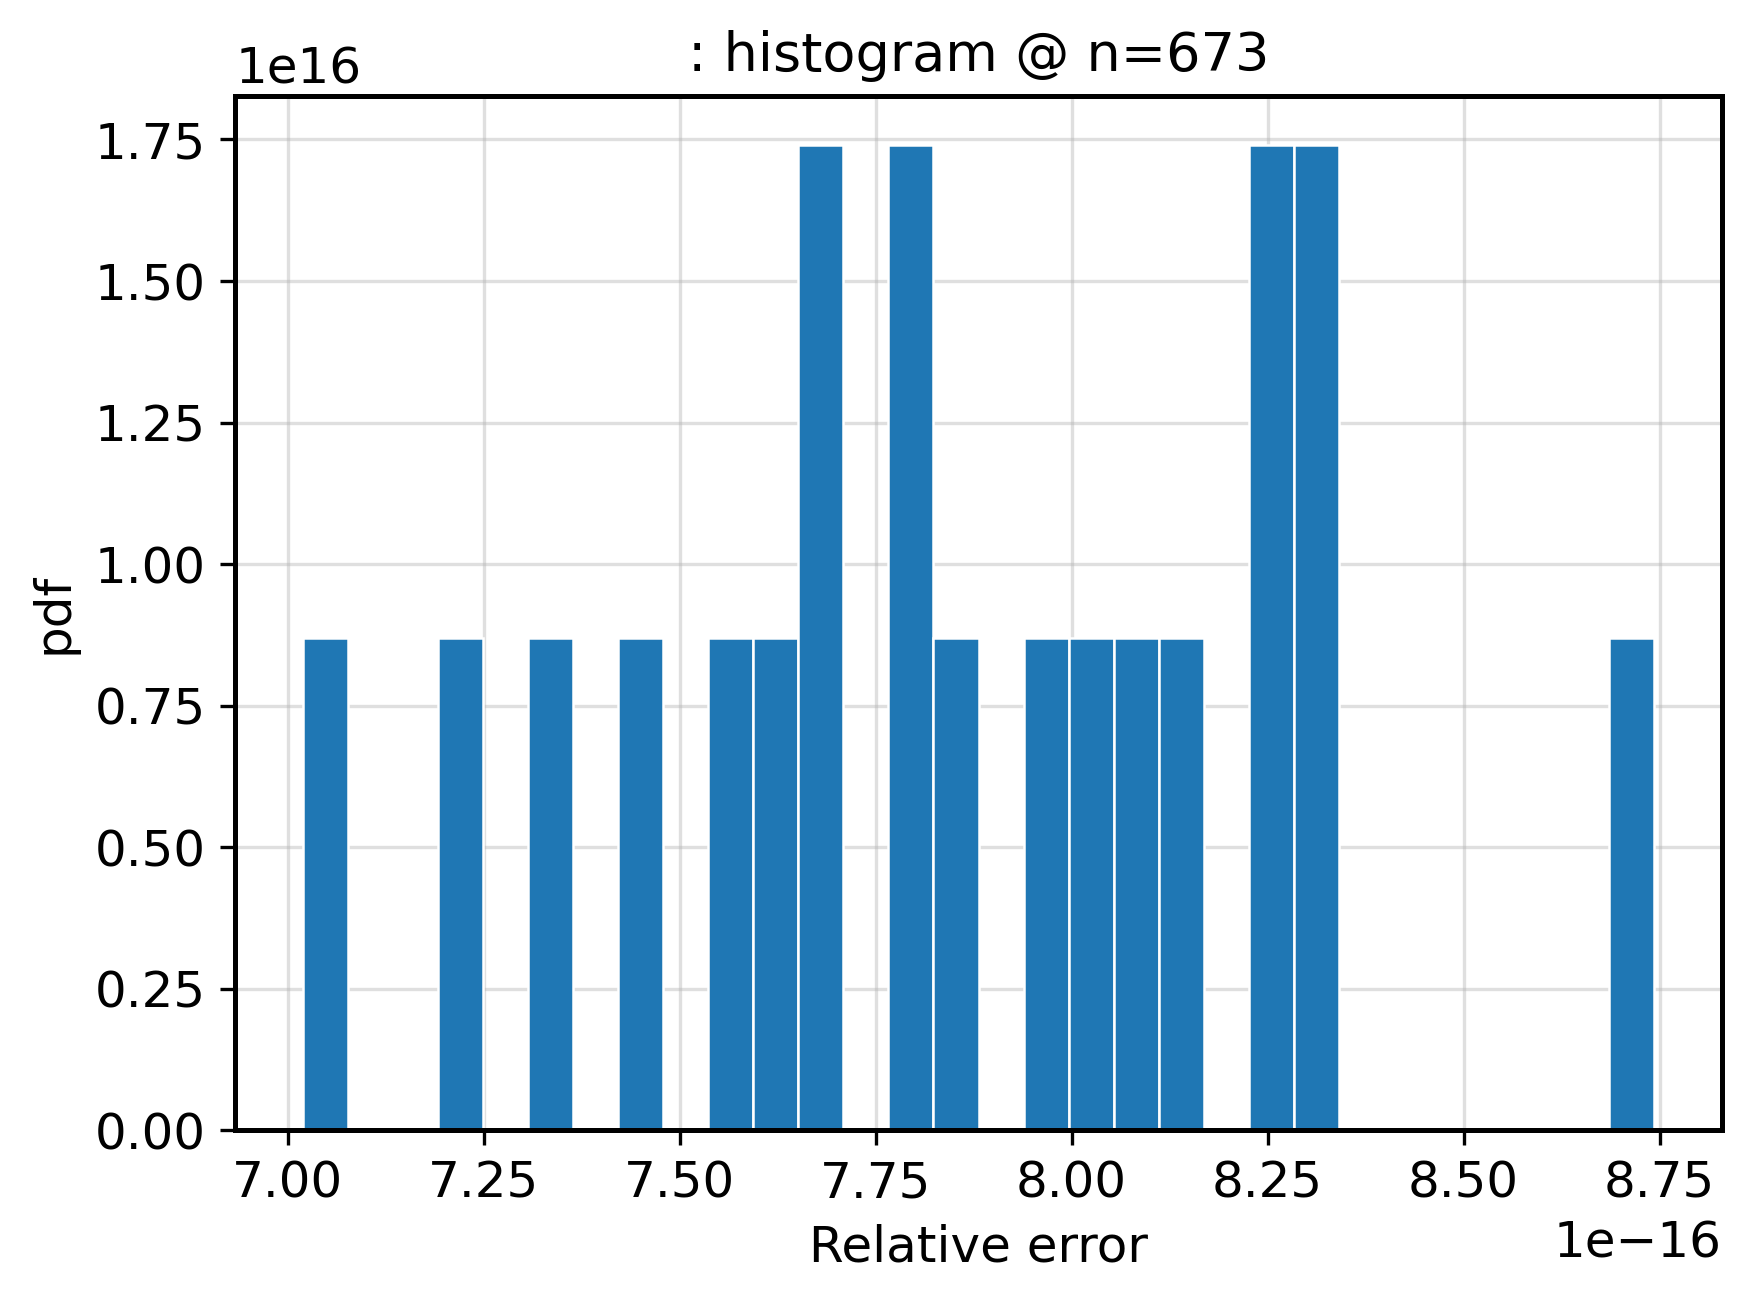

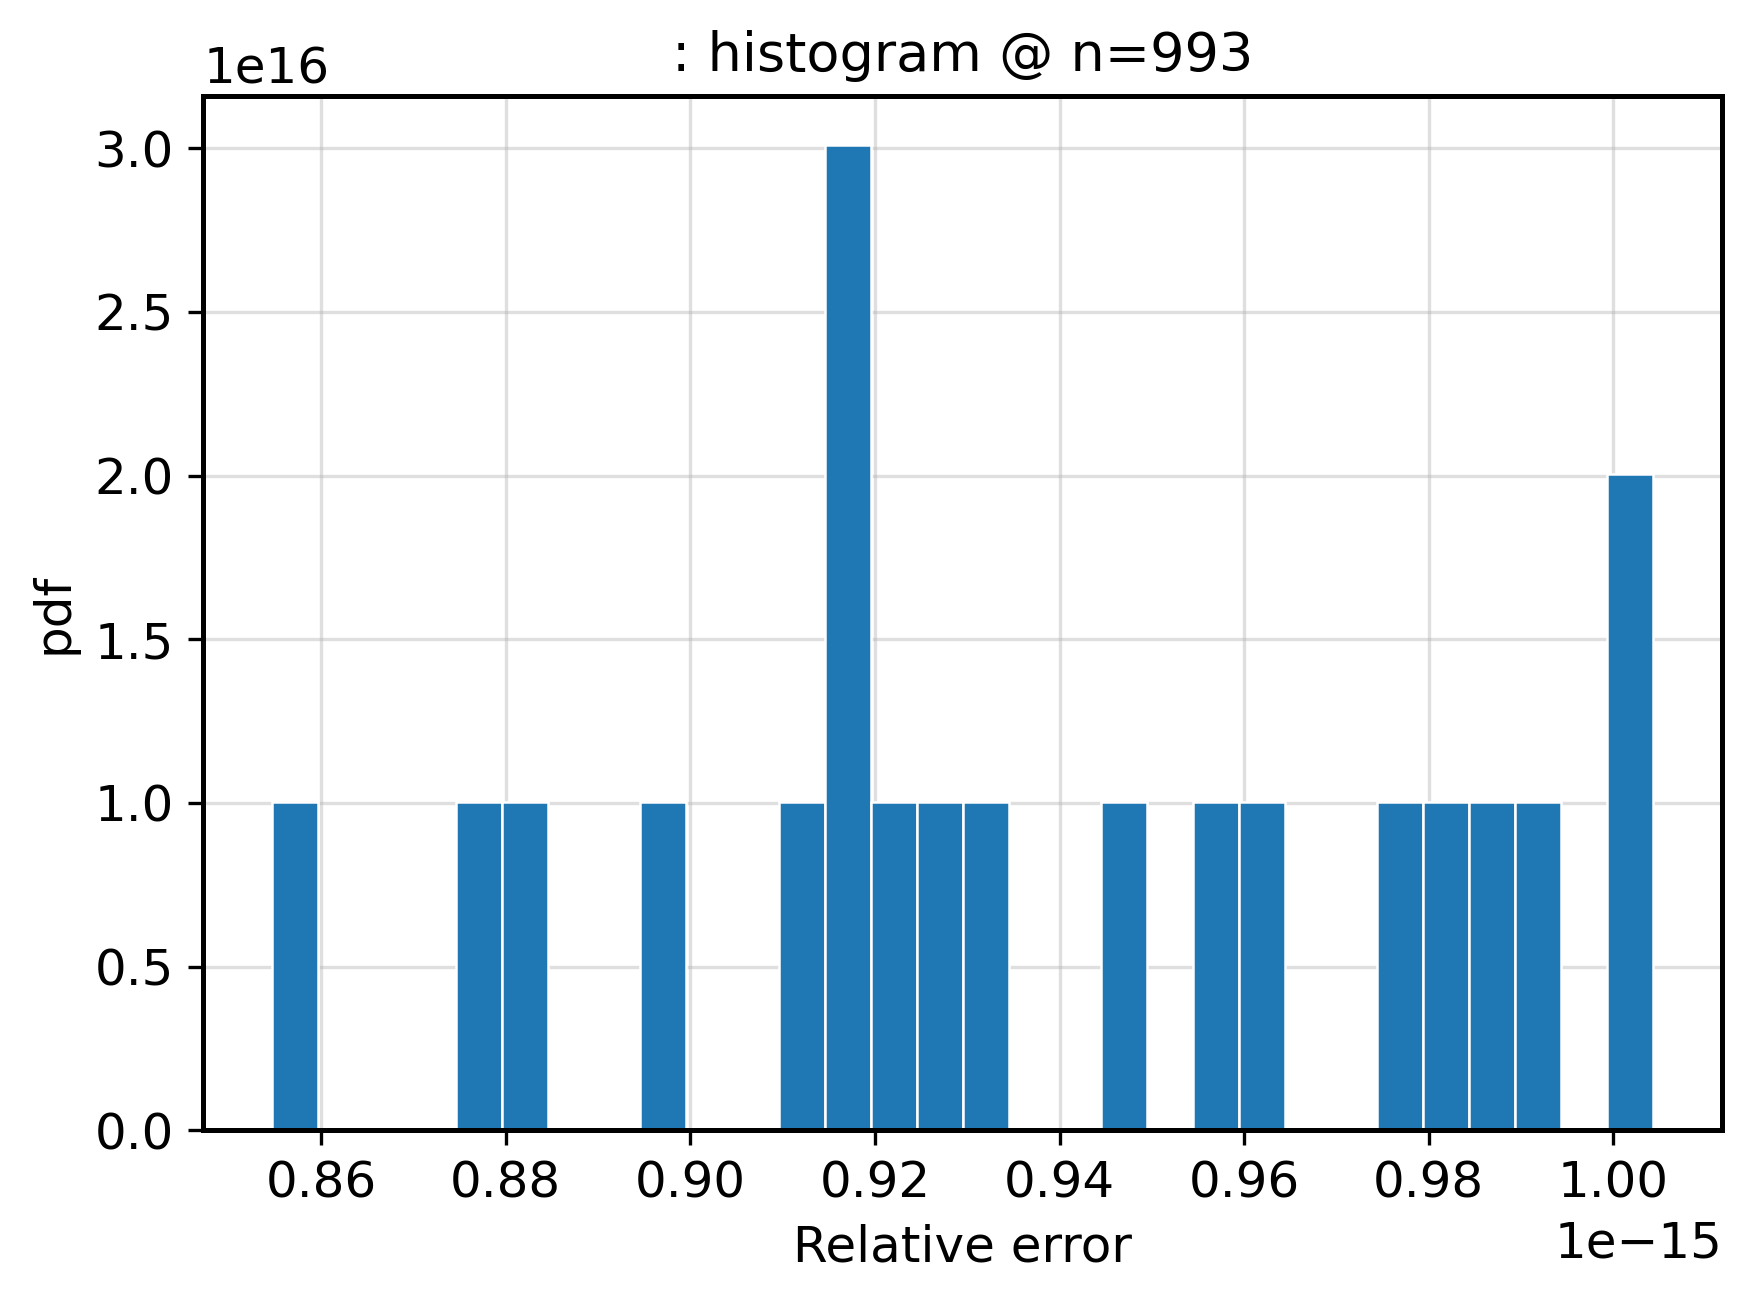

In [12]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 11,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.linewidth": 1.2,
})

def save_hist(data, xlabel, title, fname, bins):
    """One histogram per figure, same style as the line plots."""
    fig, a = plt.subplots(figsize=(6, 4.5))
    a.hist(data, bins=bins, density=True,
           color="#1f77b4", edgecolor="white", linewidth=0.6)
    a.set_xlabel(xlabel)
    a.set_ylabel("pdf")
    a.set_title(title)
    a.grid(True, which="major", alpha=0.4)
    a.set_axisbelow(True)                     # grid behind the bars
    plt.tight_layout()
    plt.savefig(f"{fname}.pdf", bbox_inches="tight")             # vector PDF
    plt.savefig(f"{fname}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Combined, across all sizes
save_hist(all_rel2, "Relative error",
          "all tests combined",
          f"subroutine2_hist_all_n{n_max}", bins=40)

pos = all_rel2[all_rel2 > 0]
save_hist(np.log10(pos), r"$\log_{10}$(Relative error)",
          r"all tests combined, $\log_{10}$",
          f"subroutine2_hist_all_log10_n{n_max}", bins=50)

# Per-n, at about n_max/3, 2*n_max/3 and n_max (never n = 1)
rep_ns = sorted(set(max(2, round(x)) for x in [n_max/3, 2*n_max/3, n_max]))
rep_idx = sorted(set(next((i for i, m in enumerate(n_list) if m >= r), K - 1) for r in rep_ns))

for j, i in enumerate(rep_idx, start=1):
    save_hist(rel2_all[i], "Relative error",
              f": histogram @ n={n_list[i]}",
              f"subroutine2_pern_n{n_max}_{j}", bins=30)